# Student 1 Mathematical Signal and DTFT

Two sinusoidal components with Gaussian noise. The DTFT is calculated using loops. Run the cells from top to bottom.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## Generate the clean signal

64 samples with angular frequencies pi/4 and pi/2 radians per sample.


In [ ]:
sample_count = 64
n = np.arange(sample_count)

amplitude_1 = 1.0
amplitude_2 = 0.5
omega_1 = np.pi / 4
omega_2 = np.pi / 2

sine_1 = amplitude_1 * np.sin(omega_1 * n)
sine_2 = amplitude_2 * np.sin(omega_2 * n)
clean_signal = sine_1 + sine_2

## Add Gaussian noise

Mean 0, standard deviation 0.2, and random seed 7.


In [ ]:
noise_standard_deviation = 0.2
rng = np.random.default_rng(7)
noise = rng.normal(0.0, noise_standard_deviation, sample_count)
noisy_signal = clean_signal + noise

## Calculate the DTFT manually

The outer loop selects a frequency and the inner loop sums the sample contributions.


In [ ]:
def manual_dtft(signal, frequencies):
    spectrum = np.zeros(len(frequencies), dtype=complex)

    for m in range(len(frequencies)):
        w = frequencies[m]
        total = 0j

        for n in range(len(signal)):
            total += signal[n] * np.exp(-1j * w * n)

        spectrum[m] = total

    return spectrum

frequencies = np.linspace(-np.pi, np.pi, 513)
spectrum = manual_dtft(noisy_signal, frequencies)

## Calculate magnitude and phase

Phase is measured in radians.


In [ ]:
magnitude = np.abs(spectrum)
phase = np.angle(spectrum)
phase[magnitude < 1e-10 * magnitude.max()] = np.nan

## Plot the results


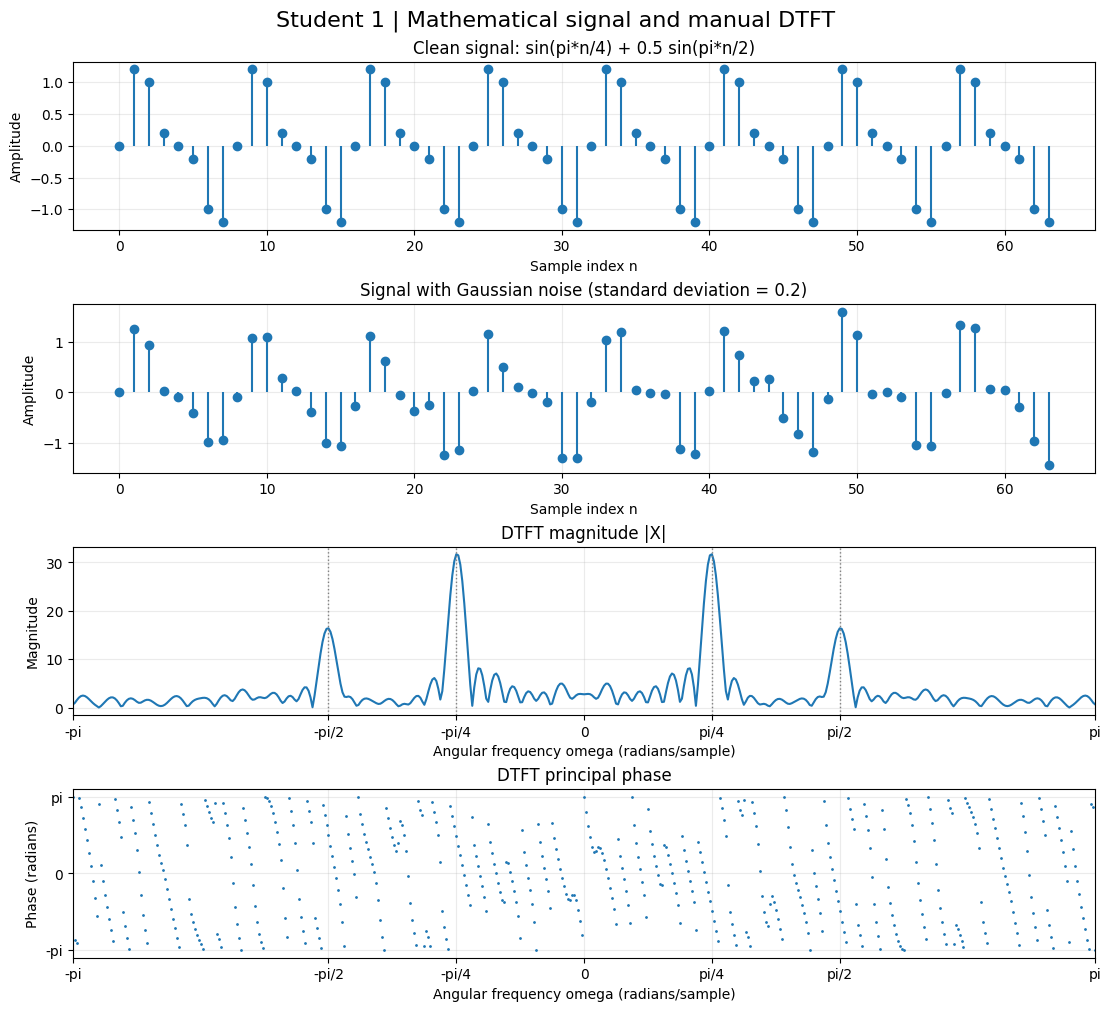

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(11, 10), layout="constrained")
fig.suptitle("Student 1 | Mathematical signal and manual DTFT", fontsize=16)

axes[0].stem(n, clean_signal, basefmt=" ")
axes[0].set_title("Clean signal: sin(pi*n/4) + 0.5 sin(pi*n/2)")
axes[0].set_xlabel("Sample index n")
axes[0].set_ylabel("Amplitude")

axes[1].stem(n, noisy_signal, basefmt=" ")
axes[1].set_title("Signal with Gaussian noise (standard deviation = 0.2)")
axes[1].set_xlabel("Sample index n")
axes[1].set_ylabel("Amplitude")

axes[2].plot(frequencies, magnitude)
axes[2].set_title("DTFT magnitude |X|")
axes[2].set_ylabel("Magnitude")
for w in (-omega_2, -omega_1, omega_1, omega_2):
    axes[2].axvline(w, color="0.5", linestyle=":", linewidth=1)

axes[3].plot(frequencies, phase, ".", markersize=2)
axes[3].set_title("DTFT principal phase")
axes[3].set_ylabel("Phase (radians)")
axes[3].set_yticks([-np.pi, 0, np.pi], ["-pi", "0", "pi"])

for ax in axes[2:]:
    ax.set_xlabel("Angular frequency omega (radians/sample)")
    ax.set_xlim(-np.pi, np.pi)
    ax.set_xticks(
        [-np.pi, -np.pi / 2, -np.pi / 4, 0, np.pi / 4, np.pi / 2, np.pi],
        ["-pi", "-pi/2", "-pi/4", "0", "pi/4", "pi/2", "pi"],
    )

for ax in axes:
    ax.grid(True, alpha=0.25)

fig.savefig("student1_dtft_plots.png", dpi=150)
plt.show()